# 07. 콘텐츠 기반 필터링 (CBF) — 최지훈 B4

제안서 3.2절. 상품 텍스트(`item_features`)를 TF-IDF로 바꾸고, 강의 module 6의 아이템 기반 CF 공식에
평점 유사도 대신 **콘텐츠 유사도**를 넣어 예측 평점을 만든다.

| 셀 | 내용 | 대략 (Video_Games) |
|---|---|---|
| 0~1 | 설정, 데이터 | 1분 |
| 2 | TF-IDF 행렬 생성·저장 | 1분 |
| 3 | 비슷한 상품 눈으로 점검 | 수 초 |
| 4 | 이웃 수 k 튜닝 (valid RMSE로 선택) | 1~3분 |
| 5 | 기준 모델·MF와 비교 (범위 × 구간) | 1분 |
| 6 | 예측값 저장: `cbf`, `mf_fb`(MF + 미등장 상품 CBF 대체) | 수 초 |
| 7 | Top-N용 유사도 원점수 정의 선택 (valid, 프로토콜 ③) | 셀 안에서 예상 시간 출력 |
| 8 | 설정·결과 저장 | 수 초 |

규칙 (docs/CONVENTIONS.md, docs/EVAL_RULES.md)
- 사용자 이력은 **train만** 쓴다 (MF와 같은 조건)
- k와 원점수 정의는 **valid로만** 고른다. test는 비교·구성요소 분석 보고용
- 예측값 파일은 `metrics.save_predictions` 형식 (`user_id, item_id, uidx, iidx, pred`)

**Toys 일반화 (11/5, 제안서 1.4절 기준 ④·5.2절)**: 아래 설정에서 `DS = 'Toys_and_Games'`, `TRANSFER_FROM = 'Video_Games'`로 바꾼다.
- 저장되는 `cbf` 예측값과 08이 쓰는 설정은 **Video_Games에서 고른 k·score_k를 그대로 적용한 값**이 된다
- Toys에서 다시 고른 값(재튜닝)은 표와 `cbf_retuned` 예측값으로 같이 남겨 재튜닝 이득을 비교한다
- Toys는 상품이 16만 개라 7번 셀이 오래 걸린다. `RUN_SCORE_SEARCH = False`로 두면 score_k 재튜닝을 건너뛴다

In [11]:
# ===== 0. 설정 =====
import os, sys, subprocess, json, time, importlib
try:
    from google.colab import drive
    drive.mount('/content/drive')
    REPO = '/content/team10-recsys'
    if not os.path.exists(REPO):
        subprocess.run(['git', 'clone', '-q', 'https://github.com/qhfl3644/team10-recsys.git', REPO], check=True)
    else:
        subprocess.run(['git', '-C', REPO, 'pull', '-q'], check=True)
except ImportError:
    REPO = os.environ.get('TEAM10_REPO', '..')
sys.path.insert(0, REPO)
from config import *

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import src.models.cbf as cbf_mod
importlib.reload(cbf_mod)                  # 레포를 pull한 뒤 다시 실행해도 새 코드가 쓰이도록
from src.eval import metrics as M
from src.models.baselines import BASELINES
from src.models.cbf import CBF, build_tfidf, save_tfidf, similar_items, TFIDF_DEFAULT

DS = 'Toys_and_Games'                      # 구축용. Toys 일반화(11/5)는 'Toys_and_Games'
TRANSFER_FROM = 'Video_Games'              # Toys 일반화 때 'Video_Games' → 그 데이터셋에서 고른 k·score_k를 그대로 적용
RUN_SCORE_SEARCH = True                    # 7번 셀 score_k 비교 실행 여부 (Toys에서 시간이 부족하면 False)
TFIDF = dict(TFIDF_DEFAULT)                # stop_words='english', min_df=3, max_df=0.5
KS = [1, 2, 3, 5, 10, None]                # 평점 예측 이웃 수 후보 (None = 평가한 상품 전부)
SCORE_KS = [1, 3, 5, None]                 # Top-N 원점수: 상위 몇 개 유사도의 평균 (1 = 최댓값)
KEYWORDS = {'Video_Games': ['mario kart', 'zelda', 'call of duty', 'minecraft', 'fifa'],
            'Toys_and_Games': ['lego', 'barbie', 'puzzle', 'nerf', 'hot wheels']}
OUT = f'{RESULT_DIR}/cbf'
os.makedirs(OUT, exist_ok=True)
klabel = lambda k: 'all' if k is None else str(k)
parse_k = lambda s: None if str(s) == 'all' else int(s)

TR = None
if TRANSFER_FROM:
    with open(f'{OUT}/{TRANSFER_FROM}_cbf_config.json', encoding='utf-8') as f:
        TR = json.load(f)
    TFIDF = dict(TR['tfidf'])               # TF-IDF 설정도 같게
    print(f'적용 모드: {TRANSFER_FROM}에서 고른 k={TR["k"]}, score_k={TR["score_k"]}를 {DS}에 그대로 적용 (재튜닝 결과는 비교용)')
print('준비 완료:', DS)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
적용 모드: Video_Games에서 고른 k=all, score_k=3를 Toys_and_Games에 그대로 적용 (재튜닝 결과는 비교용)
준비 완료: Toys_and_Games


## 1. 데이터

`item_features.parquet`의 행 순서가 `item_map`의 iidx와 같아야 TF-IDF 행 번호 = 상품 번호가 된다.

In [12]:
# ===== 1. 데이터 =====
t0 = time.time()
data = M.load_data(DS)
feat = pd.read_parquet(proc_path(DS, 'item_features'))
assert (feat['iidx'].values == np.arange(data.n_items)).all(), 'item_features가 iidx 순서가 아닙니다'
assert (feat['item_id'].astype(str).values == data.item_map['item_id'].astype(str).values).all(), 'item_map과 상품 순서가 다릅니다'
HAS_MF = all(os.path.exists(f'{PRED_DIR}/{DS}/mf_{s}.parquet') for s in ['valid', 'test'])
print(f'{DS}: 사용자 {data.n_users:,} / 상품 {data.n_items:,}')
print(f'  train {len(data.train):,} / valid {len(data.valid):,} / test {len(data.test):,}')
print(f'  train에 없는 상품이 정답인 행: valid {int((~data.seen_mask(data.valid)).sum())} / test {int((~data.seen_mask(data.test)).sum())}')
print(f'  MF 예측값 파일: {"있음" if HAS_MF else "없음 → MF 비교와 mf_fb 저장은 건너뛰고 08에서 만든다"}')
print(f'  ({time.time()-t0:.0f}초)')

Toys_and_Games: 사용자 432,264 / 상품 162,035
  train 2,997,358 / valid 432,264 / test 432,264
  train에 없는 상품이 정답인 행: valid 720 / test 1441
  MF 예측값 파일: 없음 → MF 비교와 mf_fb 저장은 건너뛰고 08에서 만든다
  (32초)


## 2. TF-IDF 행렬

- `stop_words='english'`: the, and 같은 불용어 제거
- `min_df=3`: 상품 3개 미만에만 나오는 단어 제거 (오타·모델 번호 같은 잡음)
- `max_df=0.5`: 상품 절반 넘게 나오는 단어 제거 (game 같은 너무 흔한 단어)
- L2 정규화로 행 길이를 1로 맞춰서 **내적 = 코사인 유사도**

상품 텍스트는 평점과 무관한 상품 정보라 전체 상품으로 TF-IDF를 만든다 (valid·test 평점은 쓰지 않음).

In [13]:
# ===== 2. TF-IDF =====
t0 = time.time()
X, vec = build_tfidf(feat['item_features'].values, **TFIDF)
nnz_row = np.diff(X.indptr)
print(f'TF-IDF: {X.shape[0]:,} 상품 × {X.shape[1]:,} 단어, 0이 아닌 값 {X.nnz:,}개')
print(f'  상품당 단어 수: 평균 {nnz_row.mean():.0f}, 중앙값 {np.median(nnz_row):.0f}')
print(f'  단어가 하나도 안 남은 상품: {int((nnz_row == 0).sum())}개 (이 상품은 유사도가 모두 0 → 사용자 평균으로 예측)')
idf = vec.idf_
terms = vec.get_feature_names_out()
print('  가장 흔한 단어 (IDF 낮음):', ', '.join(terms[np.argsort(idf)[:15]]))
TFIDF_PATH = f'{PROC_DIR}/{DS}/tfidf.npz'
save_tfidf(TFIDF_PATH, X, vec, TFIDF)
print(f'  저장: {TFIDF_PATH}  ({time.time()-t0:.0f}초)')

TF-IDF: 162,035 상품 × 55,824 단어, 0이 아닌 값 12,277,191개
  상품당 단어 수: 평균 76, 중앙값 71
  단어가 하나도 안 남은 상품: 2개 (이 상품은 유사도가 모두 0 → 사용자 평균으로 예측)
  가장 흔한 단어 (IDF 낮음): play, kids, toy, fun, includes, perfect, set, great, gift, accessories, preschool, quality, easy, ages, pre
  저장: /content/drive/MyDrive/Team10_RecSys/data/processed/Toys_and_Games/tfidf.npz  (42초)


## 3. 비슷한 상품 눈으로 점검

인기 상품 3개와 키워드로 찾은 상품의 이웃 5개를 본다. 같은 시리즈·장르·플랫폼이 나오면 정상이다.

In [14]:
# ===== 3. 눈으로 점검 =====
titles = feat['title'].fillna('').astype(str).values
low = pd.Series(titles).str.lower()

def show(i, n=5):
    nb, s = similar_items(X, int(i), n)
    print(f'■ {titles[i][:80]}  (train 평점 {data.item_count[i]}개)')
    for j, v in zip(nb, s):
        print(f'    {v:.3f}  {titles[j][:80]}')

for i in np.argsort(-data.item_count)[:3]:
    show(i)
for kw in KEYWORDS.get(DS, []):
    hit = np.flatnonzero(low.str.contains(kw, regex=False).values)
    if len(hit):
        show(hit[np.argmax(data.item_count[hit])])
    else:
        print(f'(키워드 "{kw}" 상품 없음)')

■ Baby Einstein Baby's First Music Teacher Developmental Toys Kit and Gift Set, Ne  (train 평점 3343개)
    0.525  STEAM Life Baby Piano Toys, Baby Girl Toys Infant Toys, Baby Music Toys Baby Lig
    0.499  Baby Einstein Octopus Orchestra Musical Toy, Ages 6 months +
    0.464  Baby Einstein Discovering Music Activity Table, Ages 6 months +
    0.444  STEAM Life - Baby Toys 3-6 Months, Baby Musical Toys Elephant, Infant Toys 0-6 M
    0.440  Baby Einstein Music Explorer Musical Toy with Lights and Melodies, Ages 3 months
■ Aurora World Flopsie Drake Dolphin 12"  (train 평점 2375개)
    0.647  Aurora World Flopsie Murphy Dog 12"
    0.625  Aurora Plush 12" Esmeralda Flopsie
    0.555  Aurora - Flopsie - 12" Charles
    0.548  Aurora - Flopsie - 12" May Bell
    0.510  Aurora - Flopsie - 12" Peanut
■ The First Years Stack N Count Cups  (train 평점 2043개)
    0.620  Stacking Toys for Toddlers 1-3 - Stacking Cups - Montessori Toys Baby Toys for 1
    0.613  Mara's Box Rainbow Star Stacking & Nesti

## 4. 이웃 수 k 튜닝

사용자가 평가한 상품 중 대상과 가장 비슷한 k개로 가중평균한다. **valid RMSE가 가장 낮은 k를 고른다.**
test 값은 구성요소 분석(제안서 5.2절, k 변화 그래프)용으로 같이 계산하지만 선택에는 쓰지 않는다.
적용 모드에서는 원래 데이터셋의 k(`K_MAIN`)를 쓰고, 여기서 고른 k는 재튜닝 비교용으로 남긴다.

  k  valid_rmse  valid_mae  test_rmse  test_mae
  1      1.3400     0.7020     1.4625    0.8001
  2      1.2097     0.6795     1.3374    0.7760
  3      1.1679     0.6732     1.2966    0.7681
  5      1.1479     0.6705     1.2769    0.7645
 10      1.1413     0.6700     1.2705    0.7636
all      1.1403     0.6701     1.2696    0.7636

valid로 고른 k = all  (valid RMSE 1.1403)
적용하는 k = all (Video_Games에서 고른 값): valid 1.1403, test 1.2696  → 재튜닝 이득(test RMSE) +0.0000
사용자 평균으로 대체된 비율 (유사도 합 0): valid 0.23%, test 0.25%
(45초)


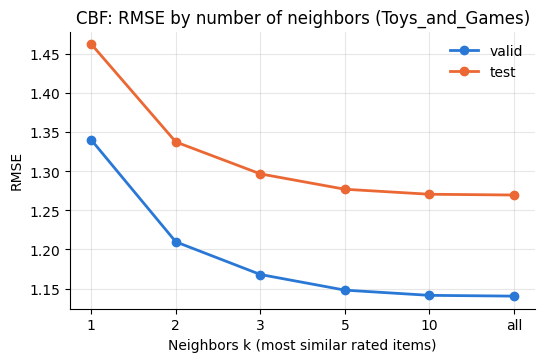

In [15]:
# ===== 4. k 튜닝 =====
t0 = time.time()
K_TR = parse_k(TR['k']) if TR else None
ks_run = KS if (TR is None or K_TR in KS) else KS + [K_TR]
cbf = CBF(X, k=5, score_k=5).fit(data.train, data.n_users, data.n_items)
uv, iv, yv = data.valid['uidx'].values, data.valid['iidx'].values, data.valid['rating'].values
ut, it, yt = data.test['uidx'].values, data.test['iidx'].values, data.test['rating'].values
pv = cbf.predict_ks(uv, iv, ks_run)
pt = cbf.predict_ks(ut, it, ks_run)
k_table = pd.DataFrame([dict(k=klabel(k), valid_rmse=M.rmse(yv, pv[k]), valid_mae=M.mae(yv, pv[k]),
                             test_rmse=M.rmse(yt, pt[k]), test_mae=M.mae(yt, pt[k])) for k in ks_run])
BEST_K = ks_run[int(k_table['valid_rmse'].values.argmin())]      # 이 데이터셋 valid로 고른 k
K_MAIN = K_TR if TR else BEST_K                                  # 저장·08에 쓰는 k
cbf.k = K_MAIN
print(k_table.round(4).to_string(index=False))
print(f'\nvalid로 고른 k = {klabel(BEST_K)}  (valid RMSE {k_table["valid_rmse"].min():.4f})')
if TR:
    r = k_table[k_table.k == klabel(K_TR)].iloc[0]
    print(f'적용하는 k = {klabel(K_TR)} ({TRANSFER_FROM}에서 고른 값): valid {r.valid_rmse:.4f}, test {r.test_rmse:.4f}'
          f'  → 재튜닝 이득(test RMSE) {r.test_rmse - k_table[k_table.k == klabel(BEST_K)].iloc[0].test_rmse:+.4f}')
print(f'사용자 평균으로 대체된 비율 (유사도 합 0): valid {cbf.fallback_rate(uv, iv)*100:.2f}%, test {cbf.fallback_rate(ut, it)*100:.2f}%')
print(f'({time.time()-t0:.0f}초)')

fig, ax = plt.subplots(figsize=(6, 3.6))
xs = np.arange(len(KS))
kt = k_table.set_index('k').loc[[klabel(k) for k in KS]]
ax.plot(xs, kt['valid_rmse'], marker='o', linewidth=2, color='#2a78d6', label='valid')
ax.plot(xs, kt['test_rmse'], marker='o', linewidth=2, color='#eb6834', label='test')
ax.set_xticks(xs, [klabel(k) for k in KS])
ax.set_xlabel('Neighbors k (most similar rated items)')
ax.set_ylabel('RMSE')
ax.set_title(f'CBF: RMSE by number of neighbors ({DS})')
ax.spines[['top', 'right']].set_visible(False); ax.grid(alpha=0.3); ax.legend(frameon=False)
fig.savefig(f'{OUT}/{DS}_cbf_k.png', dpi=200, bbox_inches='tight'); plt.show()

## 5. 기준 모델·MF와 비교 (test)

- `all`: test 전체 / `seen`: 정답 상품이 train에 있는 행만 (순수 MF 비교용)
- 구간: train 평점 수 cold(3~4) / mid(5~9) / active(10+)
- MF 예측값은 `predictions/`의 `mf_test`를 읽는다 (없으면 MF 열은 빠진다)

In [16]:
# ===== 5. 비교 =====
base = {k: c().fit(data.train, data.n_users, data.n_items) for k, c in BASELINES.items() if k != 'popularity'}
p_base = {k: m.predict(ut, it) for k, m in base.items()}
preds = {**p_base}
if HAS_MF:
    p_mf = M.load_predictions(DS, 'mf', 'test', data.test)
    preds['mf'] = p_mf
preds['cbf'] = pt[K_MAIN]
if TR and BEST_K != K_MAIN:
    preds['cbf_retuned'] = pt[BEST_K]
rt = M.rating_table(preds, data.test, data)
print('RMSE (test)')
print(rt.pivot_table(index=['scope', 'group'], columns='model', values='rmse', sort=False)[list(preds)].round(4).to_string())

un = ~data.seen_mask(data.test)
if HAS_MF:
    print(f'\ntrain에 없는 상품이 정답인 test {int(un.sum())}행: MF RMSE {M.rmse(yt[un], p_mf[un]):.4f}  vs  CBF RMSE {M.rmse(yt[un], pt[K_MAIN][un]):.4f}')

crit = M.criterion_rating_vs_baselines(pt[K_MAIN], p_base, data.test, data)
print(f'\n(참고) CBF vs 기준 모델 3개: {"모두 낮음" if crit.attrs["passed"] else "모두 낮지는 않음"}')
print(crit[['baseline', 'rmse_model', 'rmse_baseline', 'ci_lo', 'ci_hi', 'passed']].round(4).to_string(index=False))

RMSE (test)
model              global_mean  user_mean  item_mean     cbf
scope group                                                 
all   all               1.2566     1.2338     1.2173  1.2696
      cold(3-4)         1.2782     1.2811     1.2346  1.3242
      mid(5-9)          1.2554     1.2107     1.2139  1.2449
      active(10+)       1.1914     1.1316     1.1708  1.1459
seen  all               1.2559     1.2332     1.2164  1.2690
      cold(3-4)         1.2774     1.2807     1.2336  1.3238
      mid(5-9)          1.2548     1.2100     1.2132  1.2442
      active(10+)       1.1904     1.1308     1.1697  1.1450

(참고) CBF vs 기준 모델 3개: 모두 낮지는 않음
   baseline  rmse_model  rmse_baseline   ci_lo   ci_hi  passed
global_mean      1.2696         1.2566 -0.0157 -0.0105   False
  user_mean      1.2696         1.2338 -0.0372 -0.0346   False
  item_mean      1.2696         1.2173 -0.0553 -0.0494   False


## 6. 예측값 저장

- `cbf_valid`, `cbf_test`: CBF 단독 예측 (적용 모드에서는 원래 데이터셋의 k)
- `cbf_retuned_*`: 적용 모드에서 이 데이터셋 valid로 다시 고른 k의 예측 (k가 같으면 저장하지 않음)
- `mf_fb_valid`, `mf_fb_test`: MF 예측에서 **train에 없는 상품 행만 CBF로 바꾼 것** (제안서 2.1절, 성공 기준 ②의 "fallback 버전").
  MF 예측값 파일이 없으면 08에서 MF를 학습한 뒤 만든다

In [17]:
# ===== 6. 저장 =====
p_cbf = {'valid': pv[K_MAIN], 'test': pt[K_MAIN]}
for split in ['valid', 'test']:
    df = getattr(data, split)
    print(' 저장:', M.save_predictions(DS, 'cbf', split, df, p_cbf[split]))
    if TR and BEST_K != K_MAIN:
        print(' 저장:', M.save_predictions(DS, 'cbf_retuned', split, df, (pv if split == 'valid' else pt)[BEST_K]))
    if not HAS_MF:
        continue
    mf = M.load_predictions(DS, 'mf', split, df)
    un = ~data.seen_mask(df)
    fb = mf.copy(); fb[un] = p_cbf[split][un]
    print(' 저장:', M.save_predictions(DS, 'mf_fb', split, df, fb), f'(CBF로 바꾼 행 {int(un.sum())}개)')
    f_un = f'{PRED_DIR}/{DS}/mf_unseen_{split}.parquet'
    if os.path.exists(f_un):
        n_file = len(pd.read_parquet(f_un))
        print(f'   혜림 님 mf_unseen_{split} 목록 {n_file}행과 {"일치" if n_file == int(un.sum()) else "불일치 → 확인 필요"}')

 저장: /content/drive/MyDrive/Team10_RecSys/predictions/Toys_and_Games/cbf_valid.parquet
 저장: /content/drive/MyDrive/Team10_RecSys/predictions/Toys_and_Games/cbf_test.parquet


## 7. Top-N용 유사도 원점수 정의 선택

원점수 = 사용자가 train에서 평가한 상품과의 유사도 중 **상위 score_k개의 평균** (1이면 최댓값).
평가 규칙대로 **valid, 프로토콜 ③(p3_users 1만 명)의 HR@10**으로 고른다. ①②도 같은 1만 명으로 같이 본다.
인기도 기준 모델 값도 같이 출력한다. 적용 모드에서는 원래 데이터셋의 score_k를 쓰고, 여기서 고른 값은 비교용이다.

먼저 200명으로 시간을 재고 전체 예상 시간을 출력한다.

In [18]:
# ===== 7-1. 시간 측정 =====
p3 = M.load_p3_users(DS)
SCORE_K_TR = parse_k(TR['score_k']) if TR else None
score_ks_run = SCORE_KS if (TR is None or SCORE_K_TR in SCORE_KS) else SCORE_KS + [SCORE_K_TR]
t0 = time.time()
_ = cbf.score_rows_ks(p3[:200], score_ks_run)
per = (time.time() - t0) / 200
print(f'③ 원점수 계산: 사용자 1명당 {per*1000:.1f}ms → {len(p3):,}명 예상 {per*len(p3)/60:.1f}분 (순위 계산 시간 별도)')
if not RUN_SCORE_SEARCH:
    print('RUN_SCORE_SEARCH = False → 7-2 비교를 건너뛴다')

③ 원점수 계산: 사용자 1명당 140.5ms → 10,000명 예상 23.4분 (순위 계산 시간 별도)


In [20]:
# ===== 7-2. 원점수 정의 비교 (valid) =====
from src.eval.ranking import target_rank_full
score_table = pd.DataFrame()
if RUN_SCORE_SEARCH:
    t0 = time.time()
    split = 'valid'
    target = data.valid.set_index('uidx')['iidx']
    rows = []

    # ①②: 후보 파일에서 p3_users만, 원점수는 정의별로 한 번에 계산
    for proto in ['p1', 'p2']:
        cand = M.load_candidates(DS, proto, split)
        cp = cand[cand['uidx'].isin(p3)]
        S = cbf.score_ks(cp['uidx'].values, cp['iidx'].values, score_ks_run)
        for k in score_ks_run:
            uu, r = M.rank_candidates(lambda u, i, s=S[k]: s, cand, users=p3)
            hr, nd, h, _ = M.hr_ndcg(r)
            rows.append(dict(score_k=klabel(k), protocol=proto, HR10=hr, NDCG10=nd))

    # ③: 사용자 묶음마다 정의 여러 개를 한 번에 계산 (M.rank_full과 같은 방식·시드)
    rngs = {k: np.random.default_rng([SEED, 3]) for k in score_ks_run}
    ranks = {k: np.empty(len(p3), dtype=np.int64) for k in score_ks_run}
    tg = target.reindex(p3).values
    CH = 256 if data.n_items < 50_000 else 64
    for s0 in range(0, len(p3), CH):
        uu = p3[s0:s0 + CH]
        R = cbf.score_rows_ks(uu, score_ks_run)
        for k in score_ks_run:
            for r, u in enumerate(uu):
                t = int(tg[s0 + r])
                ranks[k][s0 + r] = target_rank_full(R[k][r], t, data.rated_except(int(u), t), rngs[k])
        if (s0 // CH) % 10 == 0:
            print(f'  ③ {min(s0 + CH, len(p3)):,}/{len(p3):,}명 ({time.time()-t0:.0f}초)')
    for k in score_ks_run:
        hr, nd, h, _ = M.hr_ndcg(ranks[k])
        rows.append(dict(score_k=klabel(k), protocol='p3', HR10=hr, NDCG10=nd))

    # 인기도 기준 모델 (같은 사용자)
    pop = BASELINES['popularity']().fit(data.train, data.n_users, data.n_items)
    tp, _ = M.ranking_eval({'popularity': pop}, data, split, users=p3, chunk=CH)
    for _, r in tp.iterrows():
        rows.append(dict(score_k='(인기도)', protocol=r['protocol'], HR10=r['HR10'], NDCG10=r['NDCG10']))

    score_table = pd.DataFrame(rows)
    print(score_table.pivot_table(index='score_k', columns='protocol', values='HR10', sort=False).round(4).to_string())
    p3_rows = score_table[(score_table.protocol == 'p3') & (score_table.score_k != '(인기도)')].sort_values(['HR10', 'NDCG10'], ascending=False)
    BEST_SCORE_K = score_ks_run[[klabel(k) for k in score_ks_run].index(p3_rows.iloc[0]['score_k'])]
    print(f'\nvalid로 고른 score_k = {klabel(BEST_SCORE_K)}  (valid ③ HR@10 {p3_rows.iloc[0]["HR10"]:.4f})  ({time.time()-t0:.0f}초)')
else:
    BEST_SCORE_K = SCORE_K_TR if TR else 3
SCORE_K_MAIN = SCORE_K_TR if TR else BEST_SCORE_K
cbf.score_k = SCORE_K_MAIN
print(f'저장·08에 쓰는 score_k = {klabel(SCORE_K_MAIN)}' + (f' ({TRANSFER_FROM}에서 고른 값)' if TR else ''))

  ③ 64/10,000명 (56초)
  ③ 704/10,000명 (151초)
  ③ 1,344/10,000명 (247초)
  ③ 1,984/10,000명 (346초)
  ③ 2,624/10,000명 (441초)
  ③ 3,264/10,000명 (537초)
  ③ 3,904/10,000명 (631초)
  ③ 4,544/10,000명 (728초)
  ③ 5,184/10,000명 (825초)
  ③ 5,824/10,000명 (921초)
  ③ 6,464/10,000명 (1018초)
  ③ 7,104/10,000명 (1121초)
  ③ 7,744/10,000명 (1219초)
  ③ 8,384/10,000명 (1315초)
  ③ 9,024/10,000명 (1413초)
  ③ 9,664/10,000명 (1509초)
protocol      p1      p2      p3
score_k                         
1         0.4278  0.4080  0.0255
3         0.4430  0.4154  0.0253
5         0.4446  0.4166  0.0242
all       0.4455  0.4139  0.0240
(인기도)     0.4712  0.1348  0.0055

valid로 고른 score_k = 1  (valid ③ HR@10 0.0255)  (1582초)
저장·08에 쓰는 score_k = 3 (Video_Games에서 고른 값)


## 8. 설정·결과 저장

08_hybrid가 이 파일(`results/cbf/{DS}_cbf_config.json`)에서 k와 score_k를 읽는다.

In [21]:
# ===== 8. 저장 =====
k_table.insert(0, 'dataset', DS); k_table.to_csv(f'{OUT}/{DS}_cbf_k_tuning.csv', index=False)
rt.insert(0, 'dataset', DS); rt.to_csv(f'{OUT}/{DS}_cbf_rating_test.csv', index=False)
if len(score_table):
    score_table.insert(0, 'dataset', DS); score_table.to_csv(f'{OUT}/{DS}_cbf_score_valid.csv', index=False)
cfg = dict(dataset=DS, transfer_from=TRANSFER_FROM, tfidf=TFIDF, tfidf_path=TFIDF_PATH, tfidf_shape=list(X.shape),
           k=klabel(K_MAIN), score_k=klabel(SCORE_K_MAIN),
           k_retuned=klabel(BEST_K), score_k_retuned=klabel(BEST_SCORE_K) if RUN_SCORE_SEARCH else None,
           valid_rmse=float(M.rmse(yv, p_cbf['valid'])), test_rmse=float(M.rmse(yt, p_cbf['test'])),
           test_mae=float(M.mae(yt, p_cbf['test'])))
M.save_json(cfg, f'{OUT}/{DS}_cbf_config.json')
print(json.dumps(cfg, ensure_ascii=False, indent=1))
print(f'\n저장 위치: {OUT}')

{
 "dataset": "Toys_and_Games",
 "transfer_from": "Video_Games",
 "tfidf": {
  "stop_words": "english",
  "min_df": 3,
  "max_df": 0.5
 },
 "tfidf_path": "/content/drive/MyDrive/Team10_RecSys/data/processed/Toys_and_Games/tfidf.npz",
 "tfidf_shape": [
  162035,
  55824
 ],
 "k": "all",
 "score_k": "3",
 "k_retuned": "all",
 "score_k_retuned": "1",
 "valid_rmse": 1.140260145985501,
 "test_rmse": 1.269557463000414,
 "test_mae": 0.7636150253352985
}

저장 위치: /content/drive/MyDrive/Team10_RecSys/results/cbf
